# PPP Random Urban Scene Generator — demo

Extension of the static-scene Rician pipeline: instead of one hand-built
Canary-Wharf scene with many batched receivers, we now draw **random scenes**
from a 2-D Poisson Point Process and batch receivers through each realisation.

**Model**
1. Scene = `Lx x Ly` rectangle centred on the origin, tiled by `cell_res` cells (`A_c = cell_res^2`).
2. Homogeneous PPP, intensity `lam` [pts/m^2] → `k_ij` points land in cell *(i,j)*.
3. Each point carries a fixed unit area `a_p`; the cell's built area is
   `min(k_ij * a_p, max_fill * A_c)` — one point = one unit, two points = two units,
   … until the cell is full.
4. Every occupied cell emits **one** square block **centred on the cell centre**,
   side `sqrt(A_build)`, height ~ Rayleigh(`gamma`) per ITU-R P.1410.
5. Written out as Mitsuba XML + one PLY per building → loads straight into Sionna RT.

**ITU-R P.1410 correspondence**
* `alpha = lam * a_p` — fraction of land area covered by buildings.
* `beta ≈ (1 - exp(-points_per_cell)) * 1e6 / cell_res^2` — buildings per km².
  Note this makes `cell_res` the β knob: at most one building per cell, so β is capped
  at `1e6 / cell_res^2`. Use `cell_res ≈ sqrt(1e6 / beta_target)`.
* `gamma` — Rayleigh scale = **mode** building height [m] (mean = 1.253·γ).

In [2]:
import os, sys, importlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, ".")          # scene_gen_ppp.py / scene_utils.py live here
import scene_gen_ppp as sg
importlib.reload(sg)

OUT_ROOT = "./ppp_scenes"
os.makedirs(OUT_ROOT, exist_ok=True)

In [3]:
import os, sys

# Set DRJIT_LIBLLVM_PATH directly, not via %env: that magic does not strip
# quotes, so the value reached subprocesses wrapped in literal quote characters
# and failed to load LLVM there.
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

SCRIPT_DIR = os.path.abspath(".")
sys.path.insert(0, SCRIPT_DIR)

print("Environment configured.")

Environment configured.


In [4]:
import json
%matplotlib inline

# Sionna / Mitsuba are imported here for backend setup only. The names actually
# used later (Camera, PathSolver, scene_utils, pandas, ...) are imported in the
# cells that use them.
import sionna
import sionna.rt
import mitsuba as mi

print("All imports OK.")

All imports OK.


## 1. Generate one scene

In [5]:
CFG = dict(
    Lx=1000.0, Ly=1000.0,     # scene size [m]
    cell_res=50.0,            # grid resolution [m]  -> A_c = 2500 m^2, beta <= 400/km^2
    alpha=0.15,               # target built-up area fraction (ITU alpha)
    points_per_cell=4.0,      # mean PPP points per cell (area quantisation)
    gamma=50.0,               # ITU-R P.1410 Rayleigh height scale (mode) [m]
    h_min=4.0, h_max=200.0,
    max_fill=0.98,            # leave a hairline gap between saturated cells
    min_side=3.0,             # drop sliver footprints
    seed=0,
)

# Deliberately distinct per-role params (different scattering coefficients in
# particular) so the material-override proof in cell 21 can't pass by
# coincidence -- wall/roof/ground get their OWN Sionna RadioMaterial object
# (distinct dummy ITU identity strings below) with independently overridden
# a,b,c,d / scattering_coefficient / xpd_coefficient.
WALL_PARAMS   = dict(a=5.24, b=0.0,  c=0.0462, d=0.7822, scattering_coefficient=0.3, xpd_coefficient=0.0)
ROOF_PARAMS   = dict(a=3.91, b=0.0,  c=0.0238, d=0.16,   scattering_coefficient=0.5, xpd_coefficient=0.0)
GROUND_PARAMS = dict(a=30.0, b=-0.4, c=0.15,   d=1.30,   scattering_coefficient=0.7, xpd_coefficient=0.0)

xml_path, spec = sg.generate_scene(
    os.path.join(OUT_ROOT, "scene_seed000"),
    scene_name="ppp_scene",
    building_material="itu_concrete",
    roof_material="itu_brick",
    ground_material="itu_plasterboard",
    wall_params=WALL_PARAMS,
    roof_params=ROOF_PARAMS,
    ground_params=GROUND_PARAMS,
    one_ply_per_building=True,
    **CFG,
)
spec.meta

[scene_gen_ppp] 391 buildings, alpha=0.140, beta=391/km^2, gamma_fit=49.5 m  ->  ./ppp_scenes/scene_seed000/ppp_scene.xml


{'seed': 0,
 'n_points': 1498,
 'n_cells': 400,
 'nx': 20,
 'ny': 20,
 'grid_shift_x': 31.848084366072715,
 'grid_shift_y': 13.489335688193515,
 'alpha_target': 0.15,
 'alpha_realised': 0.1404375,
 'saturated_cells': 0,
 'max_fill': 0.98,
 'min_side': 3.0,
 'gamma': 50.0,
 'h_min': 4.0,
 'h_max': 200.0,
 'n_buildings': 391,
 'mean_height': 62.15344507073649,
 'itu_alpha': 0.1404375,
 'itu_beta': 391.0,
 'itu_gamma_fit': 49.46565256085136}

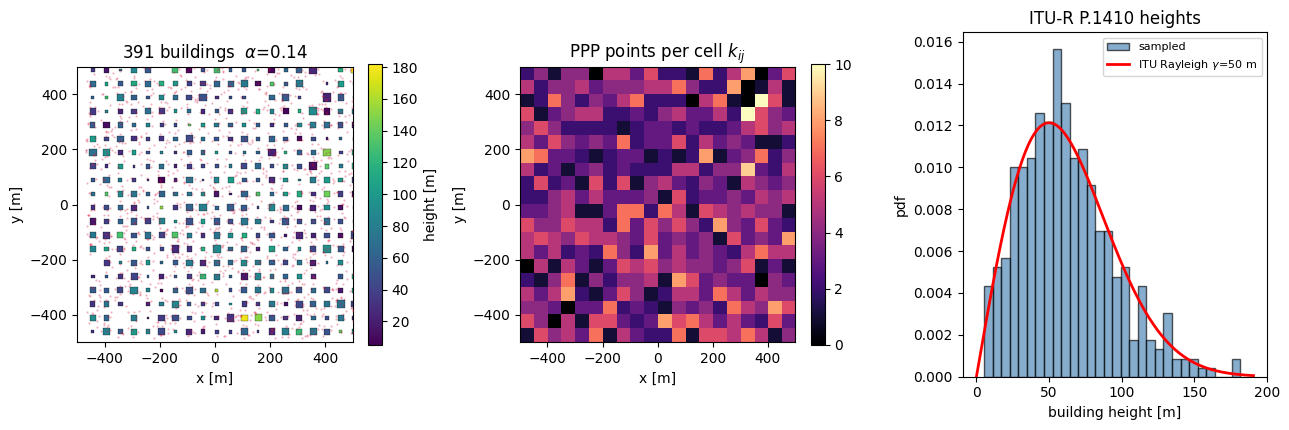

In [6]:
fig = sg.plot_scene(spec)
plt.show()

### How `points_per_cell` controls morphology
`alpha` fixes the *mean* built fraction; `points_per_cell` fixes the *granularity*.
Poisson variance is `k`, so the coefficient of variation of a cell's footprint area
is `1/sqrt(points_per_cell)`.

* **Large** `points_per_cell` (e.g. 20) → every cell gets roughly `alpha*A_c`: a very
  regular Manhattan grid, almost no empty blocks.
* **Small** `points_per_cell` (e.g. 1–3) → heavy-tailed block sizes, a real fraction of
  empty cells (`P(k=0) = exp(-points_per_cell)`), open plazas and dense clusters.

Pick it to match the morphology you want, then set `alpha` for the density.

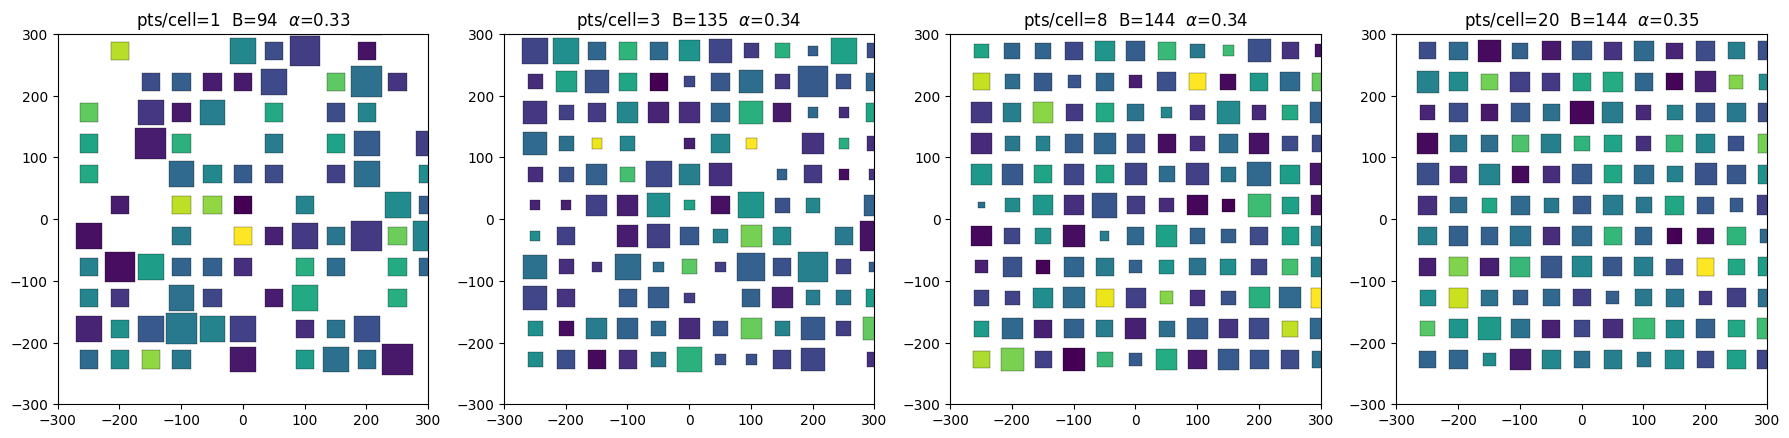

In [7]:
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, ppc in zip(axes, [1.0, 3.0, 8.0, 20.0]):
    s = sg.sample_ppp_scene(Lx=600, Ly=600, cell_res=50, alpha=0.35,
                            points_per_cell=ppc, gamma=20, seed=1)
    pc = PatchCollection([Rectangle((c[0]-w/2, c[1]-w/2), w, w)
                          for c, w in zip(s.centers, s.sides)],
                         cmap="viridis", edgecolor="k", linewidths=0.2)
    pc.set_array(s.heights)
    ax.add_collection(pc)
    ax.set_xlim(-300, 300); ax.set_ylim(-300, 300); ax.set_aspect("equal")
    ax.set_title(f"pts/cell={ppc:g}  B={s.n_buildings}  "
                 f"$\\alpha$={s.meta['itu_alpha']:.2f}")
plt.tight_layout(); plt.show()

## 2. Statistical sanity checks
The generator makes two quantitative promises — verify both empirically.

In [8]:
# (a) E[alpha_realised] == lam * a_p  (unsaturated regime)
alphas = [sg.sample_ppp_scene(Lx=500, Ly=500, cell_res=50, alpha=0.30,
                              points_per_cell=6, gamma=20, seed=k).meta['itu_alpha']
          for k in range(40)]
print(f"target alpha = 0.300   realised = {np.mean(alphas):.4f} "
      f"+/- {np.std(alphas):.4f}")

# (b) heights follow the truncated ITU Rayleigh
h = sg.rayleigh_heights(200000, gamma=20.0, h_min=4.0, h_max=120.0,
                        rng=np.random.default_rng(0))
print(f"gamma_fit = {np.sqrt(np.mean(h**2)/2):.3f}  (target 20, biased up by the h_min cut)")
print(f"mean = {h.mean():.2f} m  (Rayleigh mean = 1.253*gamma = {1.2533*20:.2f})")
print(f"range = [{h.min():.2f}, {h.max():.2f}]")

target alpha = 0.300   realised = 0.2974 +/- 0.0132
gamma_fit = 20.167  (target 20, biased up by the h_min cut)
mean = 25.48 m  (Rayleigh mean = 1.253*gamma = 25.07)
range = [4.00, 100.63]


## 3. Preview the generated scene
Three levels of *"did it actually load?"*, cheapest first.

### 3a — hard geometric verification (no Sionna needed)
Cast a downward ray at every building centre in Mitsuba and assert the roof is hit at
exactly the sampled height. This is the check that says the **geometry** is right, not
merely that the XML parsed. It raises `AssertionError` on any missing or misplaced
building, so it is safe to run as a gate in the Monte-Carlo loop.

In [9]:
report = sg.verify_scene(xml_path, spec)   # raises if any roof is missing/misplaced
report

[scene_gen_ppp] verify OK: 391/391 roofs hit, max height error 2.03e-05 m, bbox z_max 181.70 m


{'n_buildings': 391,
 'n_hit': 391,
 'max_height_error': 2.027194534548471e-05,
 'bbox_z_max': 181.70150756835938,
 'spec_z_max': 181.70150072203836,
 'n_shapes_xml': None}

### 3b — headless Mitsuba render
Works without Sionna, without a GPU and without a live notebook widget, so it also runs
on the cluster / in CI. The PNG is written into the scene directory as a provenance
record of exactly what was simulated.

[scene_gen_ppp] preview render -> ./ppp_scenes/scene_seed000/preview.png
[scene_gen_ppp] mitsuba bbox: x[-500.0,520.5] y[-500.0,502.2] z[0.0,181.7]


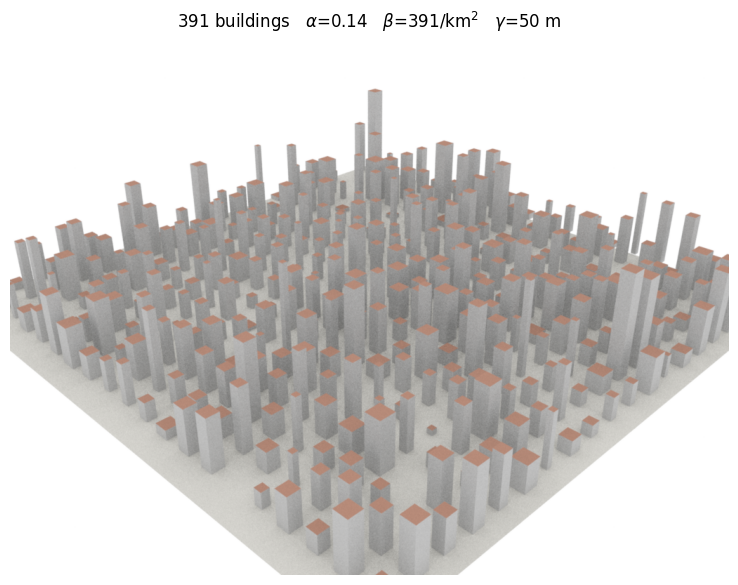

In [10]:
png = os.path.join(os.path.dirname(xml_path), "preview.png")
img = sg.render_preview(xml_path, png, spp=64, variant="llvm_ad_rgb")

from PIL import Image
fig, ax = plt.subplots(figsize=(9.5, 7))
ax.imshow(Image.open(png)); ax.axis("off")
ax.set_title(f"{spec.n_buildings} buildings   "
             f"$\\alpha$={spec.meta['itu_alpha']:.2f}   "
             f"$\\beta$={spec.meta['itu_beta']:.0f}/km$^2$   "
             f"$\\gamma$={spec.meta['gamma']:g} m")
plt.show()

## 4. Receiver placement
`free_space_grid` is an analytic drop-in for `scene_utils.build_occupancy_grid`
(same return signature), so `scene_utils.sample_rx_positions` works unchanged and
you skip the Mitsuba ray-cast entirely.

[scene_gen_ppp] free cells: 191808 / 251001 (res=2.0 m, margin=20.0 m)


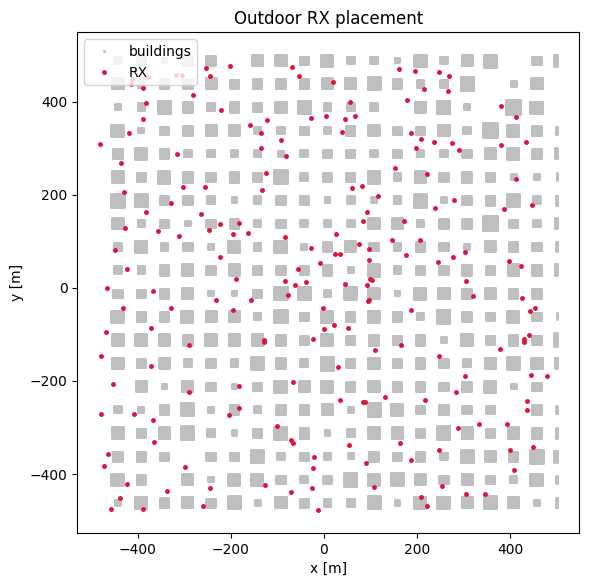

In [11]:
import scene_utils

free_xy, grid_meta = sg.free_space_grid(spec, grid_res=2.0, margin=20.0,
                                        clearance=1.0)
rx_pos = scene_utils.sample_rx_positions(free_xy, n=200, rx_height=1.5,
                                         rng=np.random.default_rng(7),
                                         grid_res=2.0)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
occ = grid_meta["occupied_xy"]
ax.plot(occ[:, 0], occ[:, 1], 's', ms=1.0, color="0.75", label="buildings")
ax.plot(rx_pos[:, 0], rx_pos[:, 1], '.', ms=5, color="crimson", label="RX")
ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Outdoor RX placement"); plt.show()

In [11]:
# Cross-check the analytic mask against the Mitsuba ray-cast once, then trust it.
free_rc, meta_rc = scene_utils.build_occupancy_grid(
    xml_path, rx_height=1.5, grid_res=2.0, margin=20.0, variant="llvm_ad_rgb")
print(f"analytic free cells : {grid_meta['n_free']}")
print(f"ray-cast free cells : {meta_rc['n_free']}")
print(f"relative difference : "
      f"{abs(grid_meta['n_free'] - meta_rc['n_free']) / meta_rc['n_free']:.3%}")

[scene_utils] Occupancy grid: 153088 valid free cells (margin=20.0 m) / 167929 total ground cells / 251001 grid cells  (res=2.0 m)
analytic free cells : 133858
ray-cast free cells : 153088
relative difference : 12.561%


## 5. Load into Sionna RT and preview there
Materials are declared with the `mat-` id prefix, so `scene.get("itu_concrete")`
resolves and the existing `build_scene_batch` material loop works untouched.

In [ ]:
# Read back the sidecar meta.json that write_sionna_scene() actually wrote
# (spec.meta itself doesn't carry the material fields) so this cell's cfg
# stays consistent with what cell 5 really generated, instead of the
# previously hardcoded/disconnected ETA_R/SIGMA/MATERIAL_NAMES values.
meta_path = os.path.join(OUT_ROOT, "scene_seed000", "ppp_scene_meta.json")
with open(meta_path) as f:
    scene_meta = json.load(f)

cfg = dict(
    SCENE_XML=xml_path,
    FREQUENCY=2.0e9,
    TX_POWER_DBM=40.0,
    SCATTERING_COEFF=0.3,     # legacy fallback -- superseded by MATERIAL_PARAMS below
    ETA_R=5.24, SIGMA=0.0462, # legacy fallback -- superseded by MATERIAL_PARAMS below
    SCENE_CENTER=[0.0, 0.0, 0.0],
    MATERIAL_NAMES=sorted({scene_meta["building_material"],
                           scene_meta["roof_material"],
                           scene_meta["ground_material"]}),
    MATERIAL_PARAMS={
        scene_meta["building_material"]: scene_meta["wall_params"],
        scene_meta["roof_material"]:      scene_meta["roof_params"],
        scene_meta["ground_material"]:    scene_meta["ground_params"],
    },
)

TX_POS = [0.0, 0.0, 200.0]   # or a satellite direction from orbital_utils
scene, B = scene_utils.build_scene_batch(rx_pos[:64].tolist(), TX_POS, cfg)
print(f"scene loaded, {B} receivers")

### 5a — confirm Sionna sees the geometry and the radio materials
Object count, scene bounds and the resolved `RadioMaterial` for each declared name.
If the `mat-` prefix were wrong, `scene.get("itu_concrete")` would come back `None`
and the material loop in `build_scene_batch` would silently do nothing — this catches that.

In [ ]:
print(f"objects in scene : {len(scene.objects)}")
print(f"expected          : {spec.n_buildings} buildings + 1 ground")

results = {}
for name in cfg["MATERIAL_NAMES"]:
    m = scene.get(name)
    if m is None:
        print(f"  !! material '{name}' NOT FOUND \u2014 check the mat- id prefix")
        continue
    results[name] = dict(eps_r=float(np.array(m.relative_permittivity).ravel()[0]),
                         sigma=float(np.array(m.conductivity).ravel()[0]),
                         S=float(np.array(m.scattering_coefficient).ravel()[0]))
    print(f"  {name}: eps_r={results[name]['eps_r']:.3f}, "
          f"sigma={results[name]['sigma']:.4f}, S={results[name]['S']:.2f}")

# Prove the per-role override actually took effect (not just "didn't crash"):
# live values must match a*f_ghz**b / c*f_ghz**d from the SAME meta.json.
f_ghz = cfg["FREQUENCY"] / 1e9
for role, mat_name in [("wall", scene_meta["building_material"]),
                       ("roof", scene_meta["roof_material"]),
                       ("ground", scene_meta["ground_material"])]:
    p = scene_meta[f"{role}_params"]
    exp_eps, exp_sig = p["a"] * f_ghz ** p["b"], p["c"] * f_ghz ** p["d"]
    got = results[mat_name]
    assert abs(got["eps_r"] - exp_eps) < 1e-6, f"{role}: eps_r mismatch"
    assert abs(got["sigma"] - exp_sig) < 1e-6, f"{role}: sigma mismatch"
    assert abs(got["S"] - p["scattering_coefficient"]) < 1e-6, f"{role}: S mismatch"

wall_r, roof_r, ground_r = (results[scene_meta[k]] for k in
                            ("building_material", "roof_material", "ground_material"))
assert wall_r != roof_r != ground_r and wall_r != ground_r, "roles are not distinct!"
print(f"\nVerified: wall/roof/ground materials are genuinely distinct "
      f"(eps_r={wall_r['eps_r']:.2f}/{roof_r['eps_r']:.2f}/{ground_r['eps_r']:.2f}, "
      f"S={wall_r['S']}/{roof_r['S']}/{ground_r['S']})")

print("sample object names:", list(scene.objects.keys())[:5])

### 5b — interactive 3D preview
`scene.preview()` opens the pan/zoom widget with the TX and all RX markers drawn in
place. **Notebook only** — it needs a live ipywidgets kernel, so it is guarded to fail
soft on a headless run (3b above is the headless substitute).

In [20]:
try:
    scene.preview(show_devices=True, show_orientations=True)
except Exception as e:
    print(f"preview unavailable ({type(e).__name__}: {e}) — "
          "use the render below or sg.render_preview() instead")

### 5c — Sionna offline render
Same view, but rasterised through Sionna's own camera so it lands in the notebook
output (and in a PNG for the paper) rather than a widget.

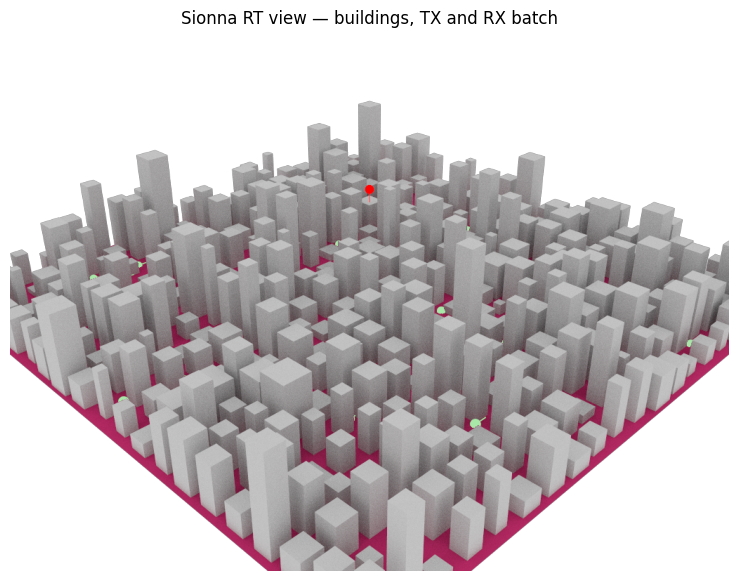

In [21]:
from sionna.rt import Camera

d = max(spec.Lx, spec.Ly)
cam = Camera(position=[-0.9 * d, -0.9 * d, 0.7 * d], look_at=[0.0, 0.0, 0.0])

out_png = os.path.join(os.path.dirname(xml_path), "sionna_preview.png")
scene.render_to_file(camera=cam, filename=out_png, resolution=[1024, 768],
                     num_samples=128, show_devices=True)

fig, ax = plt.subplots(figsize=(9.5, 7))
ax.imshow(Image.open(out_png)); ax.axis("off")
ax.set_title("Sionna RT view — buildings, TX and RX batch")
plt.show()

### 5d — propagation smoke test
The final proof that the scene is usable: paths actually solve against it.

In [ ]:
from sionna.rt import PathSolver
solver = PathSolver()
paths = solver(scene, max_depth=5, los=True, specular_reflection=True,
               diffuse_reflection=True, refraction=False,
               synthetic_array=True)
a, tau = paths.cir(normalize_delays=False, out_type="numpy")
print("CIR shape:", a.shape)
print(f"receivers with >=1 path: {int(np.sum(np.any(np.abs(a) > 0, axis=tuple(range(1, a.ndim)))))} / {B}")

# paths overlaid on the scene — the qualitative check that geometry and RT agree
try:
    scene.preview(paths=paths, show_devices=True)
except Exception as e:
    print(f"path preview unavailable ({type(e).__name__}) — rendering instead")
    scene.render_to_file(camera=cam, filename=os.path.join(
        os.path.dirname(xml_path), "sionna_paths.png"),
        paths=paths, resolution=[1024, 768], num_samples=64)

## 6. Monte-Carlo over scene realisations
The point of the extension: K-factor statistics now average over **scene randomness**
as well as receiver placement. Sweep `alpha` (density) and/or `gamma` (height scale)
and collect per-realisation statistics. Every realisation is verified and previewed,
so a malformed scene can never sneak into the results.

In [ ]:
def realisation(seed, alpha=0.35, gamma=20.0, out_root=OUT_ROOT, n_rx=64,
                preview=True):
    """Generate one random scene, verify it, place receivers."""
    d = os.path.join(out_root, f"a{alpha:.2f}_g{gamma:.0f}_s{seed:03d}")
    xml, sp = sg.generate_scene(
        d, scene_name="ppp_scene",
        Lx=1000, Ly=1000, cell_res=50,
        alpha=alpha, points_per_cell=4.0,
        gamma=gamma, h_min=4.0, h_max=120.0, seed=seed,
    )
    sg.verify_scene(xml, sp)                       # gate: raises on bad geometry
    if preview:                                     # provenance PNG per realisation
        sg.render_preview(xml, os.path.join(d, "preview.png"), spp=32,
                          variant="llvm_ad_rgb")
    fxy, _ = sg.free_space_grid(sp, grid_res=2.0, margin=20.0, clearance=1.0)
    rx = scene_utils.sample_rx_positions(fxy, n_rx, 1.5,
                                         np.random.default_rng(1000 + seed),
                                         grid_res=2.0)
    c = dict(cfg); c["SCENE_XML"] = xml
    return c, rx, sp


records = []
for alpha in [0.20, 0.35, 0.50]:
    for seed in range(3):                    # raise for production runs
        c, rx, sp = realisation(seed, alpha=alpha)
        records.append(dict(alpha_target=alpha, seed=seed,
                            xml=c["SCENE_XML"], **sp.meta))
        # --- plug your existing K-factor / channel_utils call here ---
        # scene, B = scene_utils.build_scene_batch(rx.tolist(), TX_POS, c)
        # paths = PathSolver()(scene, ...)
        # stats = channel_utils.compute_rician_stats(paths)

import pandas as pd
df = pd.DataFrame(records)
df[["alpha_target", "seed", "n_buildings", "itu_alpha", "itu_beta",
    "itu_gamma_fit", "mean_height", "saturated_cells"]]

### Contact sheet of the ensemble
A quick visual that the whole sweep produced sane, distinct scenes.

In [ ]:
pngs = [os.path.join(os.path.dirname(r["xml"]), "preview.png") for r in records]
pngs = [p for p in pngs if os.path.exists(p)]

n = len(pngs)
ncol = 3
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.4 * nrow))
for ax, p, r in zip(np.atleast_1d(axes).ravel(), pngs, records):
    ax.imshow(Image.open(p)); ax.axis("off")
    ax.set_title(f"$\\alpha$={r['itu_alpha']:.2f}  seed={r['seed']}  "
                 f"B={r['n_buildings']}", fontsize=9)
for ax in np.atleast_1d(axes).ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Reproducibility
Each scene directory holds `ppp_scene.xml`, `meshes/*.ply`,
`ppp_scene_meta.json` (all parameters + realised ITU alpha/beta/gamma),
`ppp_scene_spec.npz` (raw PPP points, cell counts, footprints, heights) and
`preview.png`. A `(seed, cfg)` pair regenerates the scene bit-for-bit, so you can ship
the JSON instead of gigabytes of meshes.